# 03 · Modeling

Baselines, hyperparameter search, cross-validated comparison, calibration, and the diagnostics a model committee would ask for:
ROC/KS, lift by decile, learning curves and the gap between test and the frozen holdout.

In [1]:
import warnings

warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from churn import config

pd.set_option("display.precision", 3)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score, learning_curve

from churn.data.ingest import X_y, load_split
from churn.decision.policy import choose_policy, customer_value, decide
from churn.models.evaluate import calibration_table, compute_metrics, expected_calibration_error, ks_statistic
from churn.models.train import build_model, candidates, fit_calibrated
from churn.monitoring.performance import bootstrap_auc_ci

train, test, holdout = load_split("train"), load_split("test"), load_split("holdout")
X_train, y_train = X_y(train)
X_test, y_test = X_y(test)
X_hold, y_hold = X_y(holdout)
cv = StratifiedKFold(5, shuffle=True, random_state=config.RANDOM_STATE)


def gini(y, p):
    return 2 * roc_auc_score(y, p) - 1

## 1. Baselines

Any model has to beat what a business analyst could do with one column. If it doesn't beat the contract-type rule by a clear margin, the complexity isn't paying for itself.

In [2]:
contract_rate = train.groupby("contract")[config.TARGET].mean()
baselines = {
    "random": np.random.default_rng(0).uniform(size=len(test)),
    "tenure only (shorter = riskier)": -X_test["tenure"],
    "contract churn rate": X_test["contract"].map(contract_rate),
    "contract + tenure rule": X_test["contract"].map(contract_rate) - X_test["tenure"] / 1000,
}
pd.DataFrame({name: {"test_gini": gini(y_test, score), "test_ks": ks_statistic(y_test, score)} for name, score in baselines.items()}).T

,test_gini,test_ks
random,-0.014,0.041
tenure only (shorter = riskier),0.535,0.403
contract churn rate,0.533,0.508
contract + tenure rule,0.623,0.520


A one-line rule (contract churn rate, ties broken by tenure) already reaches **Gini 0.62** on test. That's the bar: the models in section 4 reach about 0.73,
so they add roughly 0.11 Gini over what an analyst could do with two columns. The gain is real, but contract and tenure are doing most of the work.

## 2. Hyperparameter search

5-fold grid search on train, optimizing ROC-AUC. The pipeline trains each candidate with fixed parameters from `config`; this checks how far those are from the cross-validated optimum.

In [3]:
grids = {
    "logistic_regression": {"clf__C": [0.01, 0.1, 0.5, 1.0, 10.0]},
    "random_forest": {"clf__max_depth": [6, 8, 12], "clf__min_samples_leaf": [10, 20, 50]},
    "gradient_boosting": {"clf__n_estimators": [100, 150, 300], "clf__max_depth": [2, 3], "clf__learning_rate": [0.05, 0.1]},
}
search_rows, searches = [], {}
for name, estimator in candidates().items():
    search = GridSearchCV(build_model(estimator), grids[name], cv=cv, scoring="roc_auc", n_jobs=-1).fit(X_train, y_train)
    searches[name] = search
    current = {k: estimator.get_params()[k.removeprefix("clf__")] for k in grids[name]}
    current_score = search.cv_results_["mean_test_score"][search.cv_results_["params"].index(current)]
    search_rows.append({
        "model": name,
        "best_params": {k.removeprefix("clf__"): v for k, v in search.best_params_.items()},
        "best_cv_gini": 2 * search.best_score_ - 1,
        "pipeline_params_cv_gini": 2 * current_score - 1,
        "configs_tried": len(search.cv_results_["params"]),
    })
pd.DataFrame(search_rows).set_index("model")

,best_params,best_cv_gini,pipeline_params_cv_gini,configs_tried
model,,,,
logistic_regression,{'C': 0.1},0.687,0.686,5
random_forest,"{'max_depth': 12, 'min_samples_leaf': 10}",0.698,0.696,9
gradient_boosting,"{'learning_rate': 0.05, 'max_depth': 2, 'n_est...",0.694,0.682,12


In [4]:
gb = pd.DataFrame(searches["gradient_boosting"].cv_results_)
gb["cv_gini"] = 2 * gb["mean_test_score"] - 1
gb["cv_gini_std"] = 2 * gb["std_test_score"]
gb.filter(regex="param_|cv_gini").sort_values("cv_gini", ascending=False).head(6)

,param_clf__learning_rate,param_clf__max_depth,param_clf__n_estimators,cv_gini,cv_gini_std
0,0.05,2,100,0.694,0.018
1,0.05,2,150,0.692,0.018
6,0.10,2,100,0.690,0.020
2,0.05,2,300,0.687,0.022
7,0.10,2,150,0.686,0.021
3,0.05,3,100,0.686,0.020


The pipeline's parameters are close to the optimum but not on it:

- **Logistic regression and random forest** are within 0.002 Gini of their best configuration.
- **Gradient boosting** in the pipeline (depth 3, 150 trees) scores 0.682 in CV against 0.694 for the best grid point (depth 2, 100 trees).
  That 0.012 gap is smaller than one fold-to-fold standard deviation (~0.02), and the top six configurations are all within 0.008 of each other.

So tuning wouldn't change the picture. If I retuned, I'd move gradient boosting to shallower trees, which also lowers its train-test gap (see the learning curve below).

## 3. Cross-validated comparison

,logistic_regression,random_forest,gradient_boosting
mean,0.686,0.696,0.682
std,0.027,0.026,0.023
min,0.649,0.663,0.652
max,0.725,0.733,0.717


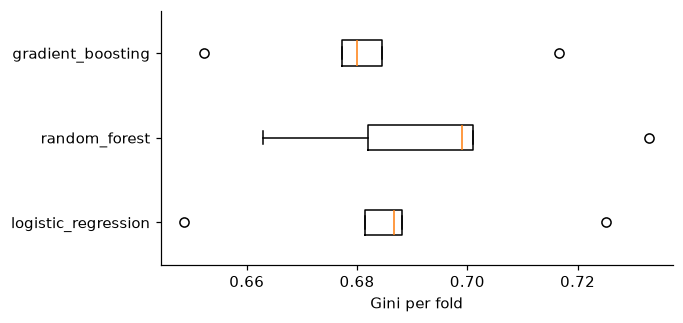

In [5]:
cv_scores = {name: 2 * cross_val_score(build_model(est), X_train, y_train, cv=cv, scoring="roc_auc", n_jobs=-1) - 1 for name, est in candidates().items()}
fig, ax = plt.subplots(figsize=(6, 3))
ax.boxplot(list(cv_scores.values()), tick_labels=list(cv_scores), orientation="horizontal")
ax.set_xlabel("Gini per fold")
pd.DataFrame(cv_scores).describe().loc[["mean", "std", "min", "max"]]

## 4. Calibrated candidates on test

Each candidate: base model on 80% of train, Platt calibrator on the other 20%. Test Gini comes with a 95% bootstrap interval.

In [6]:
fitted, rows = {}, []
for name, estimator in candidates().items():
    base, model, _, _ = fit_calibrated(estimator, X_train, y_train)
    fitted[name] = (base, model)
    proba = model.predict_proba(X_test)[:, 1]
    policy = choose_policy(y_test, proba, customer_value(X_test))
    metrics = compute_metrics(y_test, proba, decide(proba, customer_value(X_test), policy))
    low, high = bootstrap_auc_ci(y_test, proba)
    rows.append({
        "model": name,
        "gini": metrics["gini"],
        "gini_ci95": f"[{2 * low - 1:.3f}, {2 * high - 1:.3f}]",
        "ks": metrics["ks"],
        "pr_auc": metrics["pr_auc"],
        "brier": metrics["brier"],
        "ece_raw": expected_calibration_error(y_test, base.predict_proba(X_test)[:, 1]),
        "ece": metrics["ece"],
        "net_value": policy["net_value"],
    })
pd.DataFrame(rows).set_index("model")

,gini,gini_ci95,ks,pr_auc,brier,ece_raw,ece,net_value
model,,,,,,,,
logistic_regression,0.738,"[0.687, 0.791]",0.612,0.698,0.126,0.133,0.035,35696.37
random_forest,0.736,"[0.682, 0.792]",0.599,0.712,0.126,0.141,0.038,35923.26
gradient_boosting,0.731,"[0.681, 0.789]",0.597,0.683,0.127,0.018,0.021,36003.72


- **Discrimination is a three-way tie.** Test Gini is 0.731-0.738, and the 95% intervals ([0.68, 0.79]) overlap almost completely. On ranking alone there's no reason to prefer one model.
- **Calibration separates them.** Before Platt scaling, logistic regression and random forest have ECE 0.133 and 0.141, because `class_weight="balanced"` inflates their probabilities.
  After calibration all three are at 0.02-0.04.
- **Business value decides.** Gradient boosting earns the most on test ($36.0k), so it becomes the first challenger. The gap to the others is under $400, which is as much noise as signal.

## 5. ROC and KS

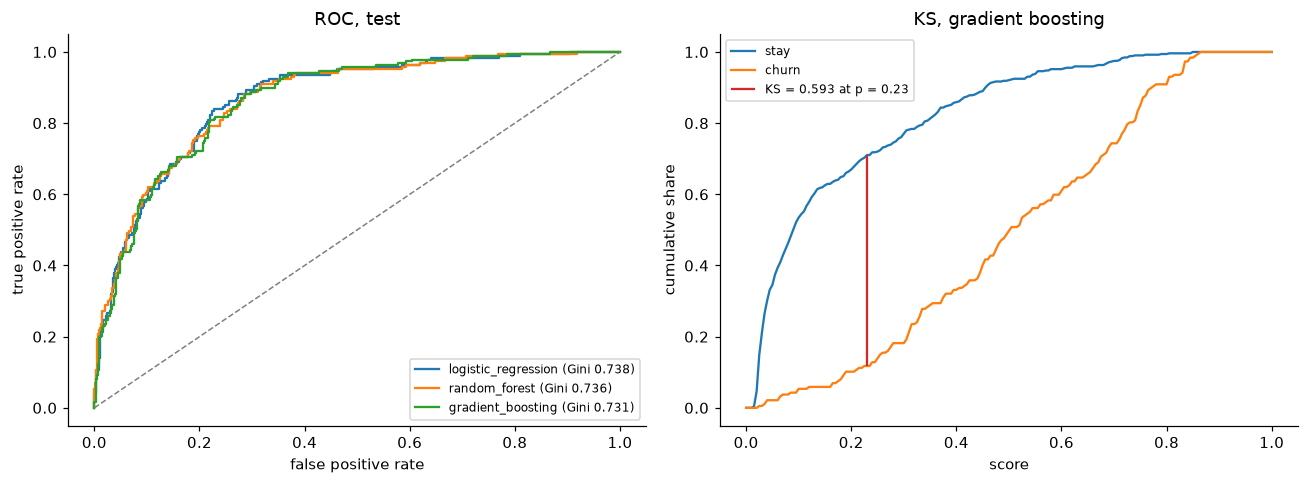

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for name, (_, model) in fitted.items():
    proba = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, proba)
    axes[0].plot(fpr, tpr, label=f"{name} (Gini {gini(y_test, proba):.3f})")
axes[0].plot([0, 1], [0, 1], color="grey", ls="--", lw=1)
axes[0].set_xlabel("false positive rate")
axes[0].set_ylabel("true positive rate")
axes[0].legend(fontsize=8)
axes[0].set_title("ROC, test")

proba = fitted["gradient_boosting"][1].predict_proba(X_test)[:, 1]
grid = np.linspace(0, 1, 201)
cdf_churn = [(proba[y_test == 1] <= t).mean() for t in grid]
cdf_stay = [(proba[y_test == 0] <= t).mean() for t in grid]
gap = np.abs(np.array(cdf_stay) - np.array(cdf_churn))
k = int(np.argmax(gap))
axes[1].plot(grid, cdf_stay, label="stay")
axes[1].plot(grid, cdf_churn, label="churn")
axes[1].vlines(grid[k], cdf_churn[k], cdf_stay[k], color="C3", label=f"KS = {gap[k]:.3f} at p = {grid[k]:.2f}")
axes[1].set_xlabel("score")
axes[1].set_ylabel("cumulative share")
axes[1].legend(fontsize=8)
axes[1].set_title("KS, gradient boosting")
fig.tight_layout()

## 6. Lift by decile

The retention team works top-down through a ranked list, so this table is what they actually experience:
how many churners sit in each tenth of the list, and how much of all churn is captured by working the top N deciles.

,customers,churners,mean_score,churn_rate,lift,cumulative_capture
decile,,,,,,
1,71,54,0.757,0.761,2.867,0.289
2,70,45,0.580,0.643,2.424,0.529
3,71,32,0.434,0.451,1.699,0.701
4,70,22,0.329,0.314,1.185,0.818
5,71,19,0.230,0.268,1.009,0.920
6,70,7,0.131,0.100,0.377,0.957
7,70,3,0.080,0.043,0.162,0.973
8,71,3,0.047,0.042,0.159,0.989
9,70,1,0.029,0.014,0.054,0.995


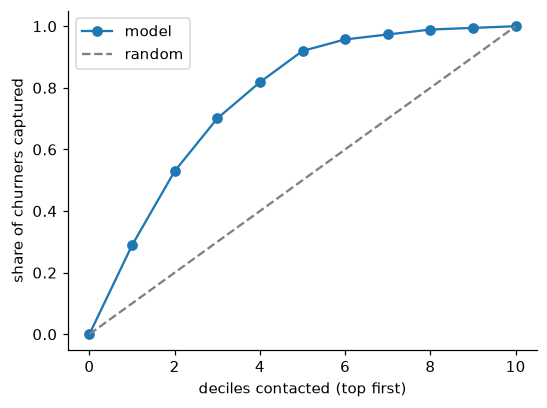

In [8]:
def lift_table(y, proba, bins=10):
    data = pd.DataFrame({"y": np.asarray(y), "p": np.asarray(proba)})
    data["decile"] = pd.qcut(data["p"].rank(method="first", ascending=False), bins, labels=range(1, bins + 1))
    table = data.groupby("decile", observed=True).agg(customers=("y", "size"), churners=("y", "sum"), mean_score=("p", "mean"))
    table["churn_rate"] = table["churners"] / table["customers"]
    table["lift"] = table["churn_rate"] / data["y"].mean()
    table["cumulative_capture"] = table["churners"].cumsum() / data["y"].sum()
    return table


lift = lift_table(y_test, proba)
fig, ax = plt.subplots(figsize=(5.5, 4))
ax.plot([0, *range(1, 11)], [0, *lift["cumulative_capture"]], "o-", label="model")
ax.plot([0, 10], [0, 1], color="grey", ls="--", label="random")
ax.set_xlabel("deciles contacted (top first)")
ax.set_ylabel("share of churners captured")
ax.legend()
lift

This is the table the retention team cares about. The **top decile is 2.9x the base churn rate** (76% of those customers leave), **the top three deciles capture 70% of all churners**,
and the top half captures 92%. Below the fifth decile churn falls under 10%, which is consistent with the decision rule contacting about 44% of customers.

## 7. Learning curve

,rows,train_gini,val_gini
0,337,0.993,0.623
1,720,0.926,0.656
2,1103,0.882,0.669
3,1486,0.854,0.678
4,1869,0.826,0.682
5,2252,0.806,0.684


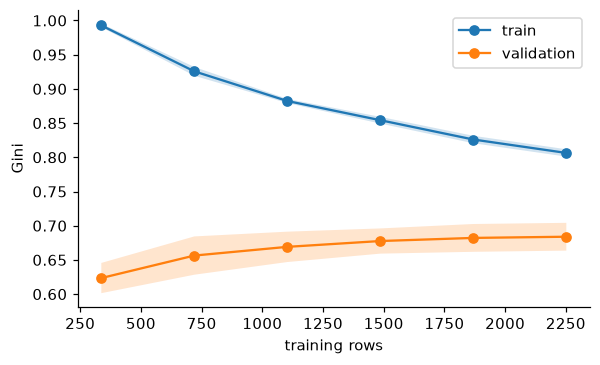

In [9]:
sizes, train_scores, val_scores = learning_curve(
    build_model(candidates()["gradient_boosting"]), X_train, y_train, cv=cv, scoring="roc_auc",
    train_sizes=np.linspace(0.15, 1.0, 6), n_jobs=-1,
)
fig, ax = plt.subplots(figsize=(6, 3.5))
for scores, label in [(train_scores, "train"), (val_scores, "validation")]:
    g = 2 * scores - 1
    ax.plot(sizes, g.mean(axis=1), "o-", label=label)
    ax.fill_between(sizes, g.mean(axis=1) - g.std(axis=1), g.mean(axis=1) + g.std(axis=1), alpha=0.2)
ax.set_xlabel("training rows")
ax.set_ylabel("Gini")
ax.legend()
pd.DataFrame({"rows": sizes, "train_gini": (2 * train_scores - 1).mean(axis=1), "val_gini": (2 * val_scores - 1).mean(axis=1)})

Validation Gini is still creeping up at full size (0.682 → 0.684 over the last 400 rows), so more data would help only marginally.
The bigger signal is the gap: train Gini 0.81 against validation 0.68. Depth-3 trees memorize part of the training set.
It passes the 10-point gate (measured on the calibrated model), but it's another argument for the shallower configuration from the grid search.

## 8. Calibration before and after Platt scaling

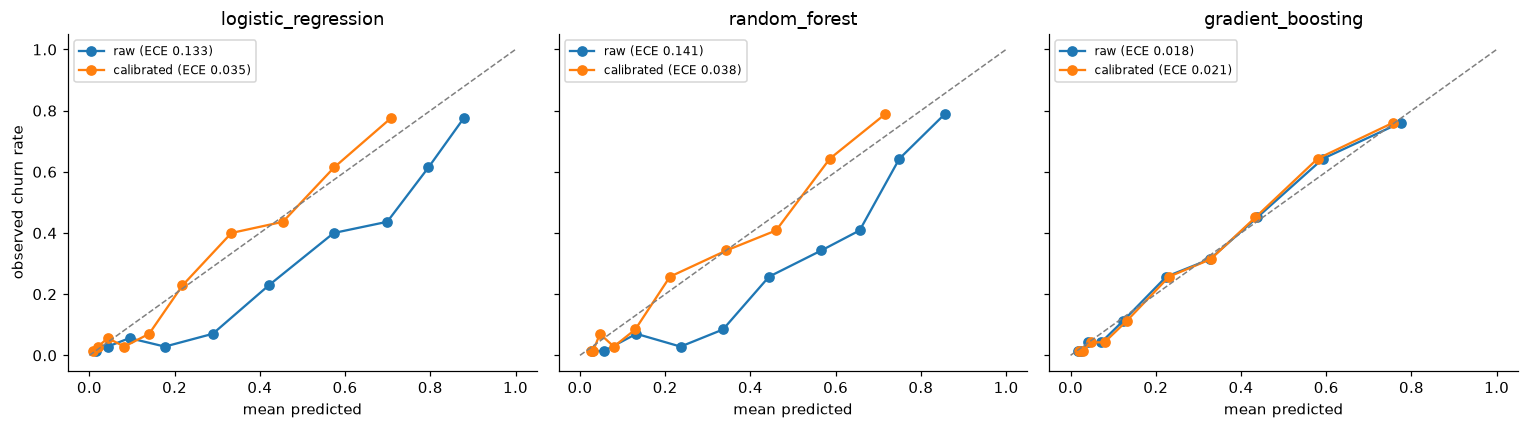

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, (name, (base, model)) in zip(axes, fitted.items()):
    for label, p in [("raw", base.predict_proba(X_test)[:, 1]), ("calibrated", model.predict_proba(X_test)[:, 1])]:
        table = calibration_table(y_test, p)
        ax.plot(table["mean_predicted"], table["observed_rate"], "o-", label=f"{label} (ECE {expected_calibration_error(y_test, p):.3f})")
    ax.plot([0, 1], [0, 1], color="grey", ls="--", lw=1)
    ax.set_title(name)
    ax.set_xlabel("mean predicted")
    ax.legend(fontsize=8)
axes[0].set_ylabel("observed churn rate")
fig.tight_layout()

The reliability curves show what the ECE numbers summarize. Raw logistic regression and random forest sit above the diagonal across the whole range, overestimating churn
at every score level. After Platt scaling they track the diagonal. Gradient boosting barely moves because it was already calibrated (log-loss objective, no class weighting).

## 9. Test vs the frozen holdout

In [11]:
comparison = pd.DataFrame({
    name: {"test_gini": gini(y_test, m.predict_proba(X_test)[:, 1]), "holdout_gini": gini(y_hold, m.predict_proba(X_hold)[:, 1])}
    for name, (_, m) in fitted.items()
}).T
comparison["drop"] = comparison["test_gini"] - comparison["holdout_gini"]
comparison

,test_gini,holdout_gini,drop
logistic_regression,0.738,0.670,0.067
random_forest,0.736,0.663,0.073
gradient_boosting,0.731,0.667,0.064


All three models lose 0.06-0.07 Gini from test to holdout. The test set chooses the decision rule and the winning candidate, so it is slightly fitted to those choices.
That's exactly why promotion never looks at test, and why the holdout is frozen and hashed.

## Summary

| Question | Answer |
|---|---|
| Does ML beat a business rule? | Yes, by ~0.11 Gini (0.62 → 0.73) |
| Which algorithm? | Statistically tied on ranking; chosen by calibrated business value |
| Is tuning worth it? | Not much: every candidate is within one std of its CV optimum |
| Is calibration necessary? | Yes for class-weighted models (ECE 0.13-0.14 → 0.03-0.04) |
| How much does the ranked list help? | Top 30% of the list holds 70% of churners |
| How optimistic is test? | 0.06-0.07 Gini, which the frozen holdout absorbs |